In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')


¡PyLTSpice ya estaba instalado y listo para usar!


In [2]:
import re
import os
import shutil
import subprocess
from PyLTSpice import RawRead

parametros_ldo = {}
graficas_ldo = {}

# Localización dinámica de Ngspice
NGSPICE_BIN = shutil.which('ngspice') or '/foss/tools/ngspice/bin/ngspice' or '/usr/bin/ngspice'

def one_pvt(netlist_path, raw_path, temp, vdd, proces):
    print(f'Ejecutando corner: temperatura = {temp}, VDD = {vdd}, Proceso = {proces}')
    
    # Asegurar que el directorio de salida raw_path exista
    os.makedirs(raw_path, exist_ok=True)
    
    # Asegurar que el netlist fuente exista y no esté vacío
    if not os.path.exists(netlist_path) or os.path.getsize(netlist_path) == 0:
        cand = ['/headless/.xschem/simulations/ldo_tb.spice', '/home/luigy/eda/designs/LDO-sky130/xschem/ldo_tb.spice']
        found = False
        for c in cand:
            if os.path.exists(c) and os.path.getsize(c) > 500:
                with open(c, 'r', encoding='utf-8', errors='ignore') as src, open(netlist_path, 'w', encoding='utf-8') as dst:
                    dst.write(src.read())
                found = True
                break
        if not found:
            print(f'Error: El archivo netlist {netlist_path} no existe o está vacío.')
            return
    
    # ====================================================================
    # PASO 1 y 2: LEER Y MODIFICAR EL CONTENIDO 
    # ====================================================================
    with open(netlist_path, 'r', encoding='utf-8', errors='ignore') as archivo:
        contenido = archivo.read()

    patron_corner = r'(\.lib\s+.*?sky130\.lib\.spice\s+)\w+'
    contenido = re.sub(patron_corner, rf'\g<1>{proces}', contenido)
    
    patron_temp = r'(\.option\s+temp=)[-\d\.]+'
    contenido = re.sub(patron_temp, rf'\g<1>{temp}', contenido)
    
    patron_vdd = r'(\.param\s+VDD\s*=\s*)[-\d\.]+'
    contenido = re.sub(patron_vdd, rf'\g<1>{vdd}', contenido)
    
    # ====================================================================
    # PASO 3: SOBRESCRIBIR EL ARCHIVO
    # ====================================================================
    with open(netlist_path, 'w', encoding='utf-8') as archivo:
        archivo.write(contenido)

    # ====================================================================
    # PASO 4: SIMULAR
    # ====================================================================
    comando = [NGSPICE_BIN, '-b', netlist_path]
    resultado = subprocess.run(comando, capture_output=True, text=True, cwd=raw_path)
    mi_log = resultado.stdout
    
    if resultado.returncode != 0 and 'error:' in resultado.stderr.lower():
        print('La simulación falló. Aquí está el error de Ngspice:\n')
        print(resultado.stderr)
        return
    else:
        print('¡Simulación terminada con éxito!')
    
    # ====================================================================
    # PASO 5: EXTRAER PARÁMETROS DEL LOG
    # ====================================================================
    patron = r'([a-zA-Z0-9_]+)\s*=\s*([+-]?\d+\.?\d*[eE]?[+-]?\d*)'
    coincidencias = re.findall(patron, mi_log)
    
    nombre_llave = f'{vdd}[V]_{temp}[C]_{proces}'
    
    parametros_ldo[nombre_llave] = {}
    graficas_ldo[nombre_llave] = {}

    for nombre, valor in coincidencias:
        n_lower = nombre.strip().lower()
        if n_lower not in ['tnom', 'temp']:
            parametros_ldo[nombre_llave][n_lower] = float(valor)
    
    # ====================================================================
    # PASO 6: EXTRAER VECTORES DE LOS .RAW USANDO PyLTSpice.RawRead
    # ====================================================================
    try:
        raw_tran = RawRead(os.path.join(raw_path, 'LDO_tran_picos.raw'))
        graficas_ldo[nombre_llave]['time'] = raw_tran.get_trace('time').get_wave()
        graficas_ldo[nombre_llave]['t_vo'] = raw_tran.get_trace('v(vo)').get_wave()
    except Exception as e:
        print(f'Aviso: no se pudo leer LDO_tran_picos.raw: {e}')

    try:
        raw_ac_stability = RawRead(os.path.join(raw_path, 'LDO_ac_estability.raw'))
        graficas_ldo[nombre_llave]['frecuencia'] = raw_ac_stability.get_trace('frequency').get_wave()
        graficas_ldo[nombre_ldo_key if 'nombre_ldo_key' in locals() else 'nombre_llave'] = {}
        graficas_ldo[nombre_llave]['fase'] = raw_ac_stability.get_trace('fase_deg').get_wave()
        graficas_ldo[nombre_llave]['ganancia'] = raw_ac_stability.get_trace('loop_gain_db').get_wave()
    except Exception as e:
        print(f'Aviso: no se pudo leer LDO_ac_estability.raw: {e}')

    try:
        raw_ac_psrr = RawRead(os.path.join(raw_path, 'LDO_ac_psrr.raw'))
        graficas_ldo[nombre_llave]['psrr'] = raw_ac_psrr.get_trace('psrr_db').get_wave()
    except Exception as e:
        print(f'Aviso: no se pudo leer LDO_ac_psrr.raw: {e}')

    try:
        raw_dc_line = RawRead(os.path.join(raw_path, 'LDO_dc_line.raw'))
        trace_v = 'v(v-sweep)' if 'v(v-sweep)' in raw_dc_line.get_trace_names() else 'v-sweep'
        graficas_ldo[nombre_llave]['dc_vin'] = raw_dc_line.get_trace(trace_v).get_wave()
        graficas_ldo[nombre_llave]['dc_vin_vo'] = raw_dc_line.get_trace('v(vo)').get_wave()
    except Exception as e:
        print(f'Aviso: no se pudo leer LDO_dc_line.raw: {e}')

    try:
        raw_dc_load = RawRead(os.path.join(raw_path, 'LDO_dc_load.raw'))
        trace_i = 'i(i-sweep)' if 'i(i-sweep)' in raw_dc_load.get_trace_names() else 'i-sweep'
        graficas_ldo[nombre_llave]['dc_iload'] = raw_dc_load.get_trace(trace_i).get_wave()
        graficas_ldo[nombre_llave]['dc_iload_vo'] = raw_dc_load.get_trace('v(vo)').get_wave()
    except Exception as e:
        print(f'Aviso: no se pudo leer LDO_dc_load.raw: {e}')

    print('¡Extracción completada!')


In [3]:
# ==============================================================================
# BUCLE DE EJECUCIÓN
# ==============================================================================
temperaturas = [-40, 27, 125]
voltajes = [1.62, 1.8, 1.98] 
corners_proceso = [
    'tt', 'sf', 'ff', 'ss', 'fs', 'll', 'hh', 'hl', 'lh',
    'sf_ll', 'sf_hh', 'sf_hl', 'sf_lh', 'ff_ll', 'ff_hh', 'ff_hl', 'ff_lh',
    'ss_ll', 'ss_hh', 'ss_hl', 'ss_lh', 'fs_ll', 'fs_hh', 'fs_hl', 'fs_lh'
]
#25procesos
# Resolución dinámica de rutas
netlist_path = '/headless/.xschem/simulations/ldo_tb.spice' if os.path.exists('/headless') else os.path.expanduser('~/.xschem/simulations/ldo_tb.spice')
raw_path = '/foss/designs/LDO-sky130/xschem/spice_raw_log/raw/' if os.path.exists('/foss') else '/home/luigy/eda/designs/LDO-sky130/xschem/spice_raw_log/raw/'

total_sim = len(temperaturas) * len(voltajes) * len(corners_proceso)
contador = 1

print(f'Iniciando barrido secuencial PVT: {total_sim} simulaciones programadas.\n')

for temp in temperaturas:
    for vdd in voltajes:
        for proces in corners_proceso:
            print(f'--- Progreso: {contador}/{total_sim} ---')
            one_pvt(netlist_path, raw_path, temp, vdd, proces)
            contador += 1

print('\n¡Barrido masivo finalizado con éxito!')


Iniciando barrido secuencial PVT: 225 simulaciones programadas.

--- Progreso: 1/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.62, Proceso = tt
¡Simulación terminada con éxito!
¡Extracción completada!
--- Progreso: 2/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.62, Proceso = sf
¡Simulación terminada con éxito!
¡Extracción completada!
--- Progreso: 3/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.62, Proceso = ff
¡Simulación terminada con éxito!
¡Extracción completada!
--- Progreso: 4/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.62, Proceso = ss
¡Simulación terminada con éxito!
¡Extracción completada!
--- Progreso: 5/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.62, Proceso = fs
¡Simulación terminada con éxito!
¡Extracción completada!
--- Progreso: 6/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.62, Proceso = ll
¡Simulación terminada con éxito!
¡Extracción completada!
--- Progreso: 7/225 ---
Ejecutando corner: temperatura = -40, VDD = 1.6

In [20]:
import pandas as pd

# 1. Convertir el diccionario en la tabla principal
df_resultados = pd.DataFrame.from_dict(parametros_ldo, orient='index')

# 2. Calcular Mínimos, Máximos (y el promedio, que es muy útil)
# .agg(['min', 'max', 'mean']) calcula los extremos
# .T (Transponer) voltea la tabla para que sea mucho más fácil de leer
df_resumen = df_resultados.agg(['min', 'max', 'mean']).T

# 3. Mostrar la tabla resumen en la pantalla
print("--- Resumen PVT: Peor y Mejor Caso de cada Especificación ---")
display(df_resumen)

# 4. Guardar en Excel con múltiples pestañas (hojas)
try:
    # Intenta guardar en Excel (requiere la librería openpyxl)
    with pd.ExcelWriter("Reporte_Completo_LDO.xlsx") as writer:
        df_resultados.to_excel(writer, sheet_name="225_Corners")
        df_resumen.to_excel(writer, sheet_name="Resumen_Peores_Casos")
    print("\n¡Reporte exportado exitosamente a 'Reporte_Completo_LDO.xlsx'!")
    print("(Revisa la segunda hoja del Excel para ver el resumen)")
    
except ImportError:
    # Si la imagen de Docker no tiene instalado openpyxl, guarda en CSV nativo
    print("\nLibrería de Excel no detectada. Guardando como CSV...")
    df_resultados.to_csv("225_Corners_LDO.csv")
    df_resumen.to_csv("Resumen_Peores_Casos_LDO.csv")
    print("¡Tablas exportadas exitosamente a formato CSV!")

--- Resumen PVT: Peor y Mejor Caso de cada Especificación ---


,min,max,mean
ugb,345049.000000,1.311800e+06,881667.440000
fase_ugb,52.722700,8.506340e+01,71.505667
ganancia_banda_plana,63.748900,8.337440e+01,78.240281
margen_fase,52.722700,8.506340e+01,71.505668
gananciapsrr_1,48.374900,6.396940e+01,57.105992
gananciapsrr_1k,48.257800,6.259390e+01,56.032349
gananciapsrr_10k,35.525200,4.818890e+01,43.824877
gananciapsrr_1m,24.823700,3.003720e+01,27.148795
voload_max,1.192270,1.194870e+00,1.193393
at,1.300000,1.300000e+00,1.300000



Librería de Excel no detectada. Guardando como CSV...
¡Tablas exportadas exitosamente a formato CSV!


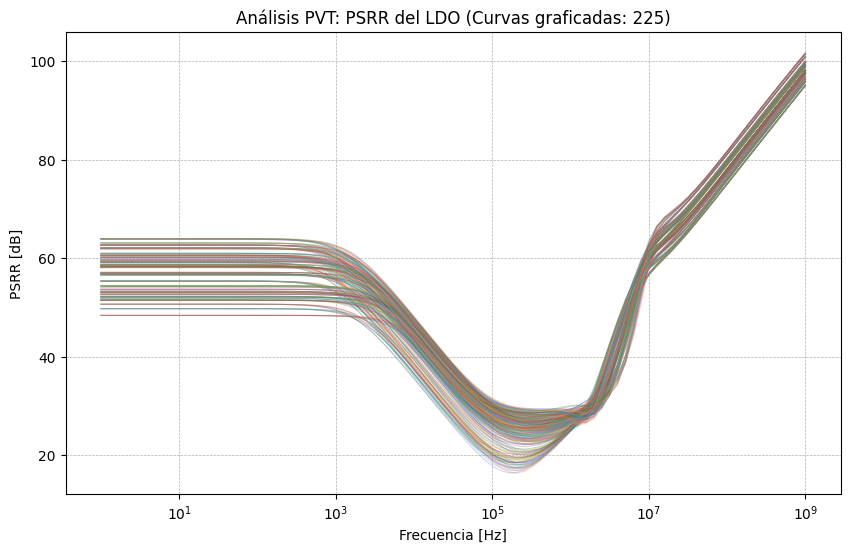

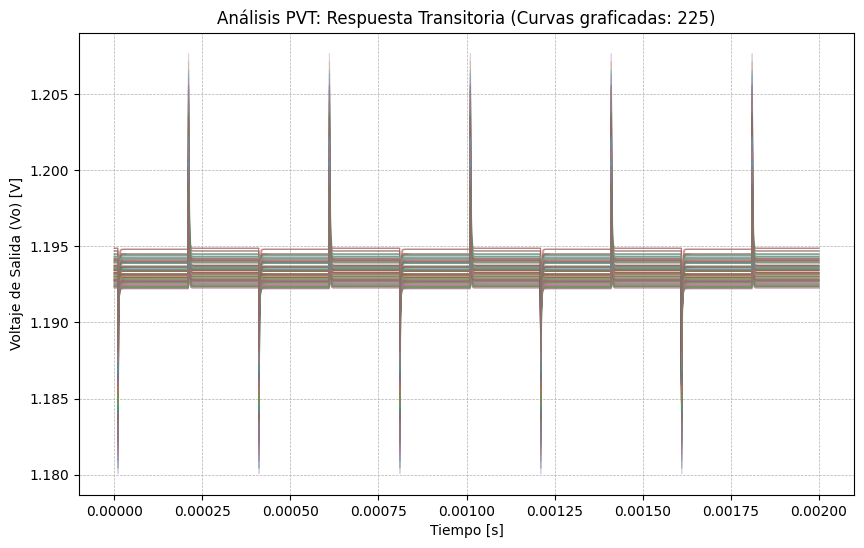

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# ====================================================================
# 1. GRAFICAR PSRR (Bode - Escala Logarítmica)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_psrr = 0

for llave, curvas in graficas_ldo.items():
    # Verificamos que la simulación tenga datos antes de extraerlos
    if "frecuencia" in curvas and "psrr" in curvas:
        x_freq = np.abs(curvas["frecuencia"])
        y_psrr = np.real(curvas["psrr"])
        
        plt.semilogx(x_freq, y_psrr, linewidth=0.8, alpha=0.3)
        exitosas_psrr += 1

plt.title(f"Análisis PVT: PSRR del LDO (Curvas graficadas: {exitosas_psrr})")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("PSRR [dB]")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.savefig("psrr.png", dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# 2. GRAFICAR RESPUESTA TRANSITORIA (Undershoot / Overshoot)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_tran = 0

for llave, curvas in graficas_ldo.items():
    if "time" in curvas and "t_vo" in curvas:
        x_time = np.real(curvas["time"])
        y_vo = np.real(curvas["t_vo"])
        
        plt.plot(x_time, y_vo, linewidth=0.8, alpha=0.3)
        exitosas_tran += 1

plt.title(f"Análisis PVT: Respuesta Transitoria (Curvas graficadas: {exitosas_tran})")
plt.xlabel("Tiempo [s]")
plt.ylabel("Voltaje de Salida (Vo) [V]")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.savefig("tran.png", dpi=300, bbox_inches='tight')
plt.show()


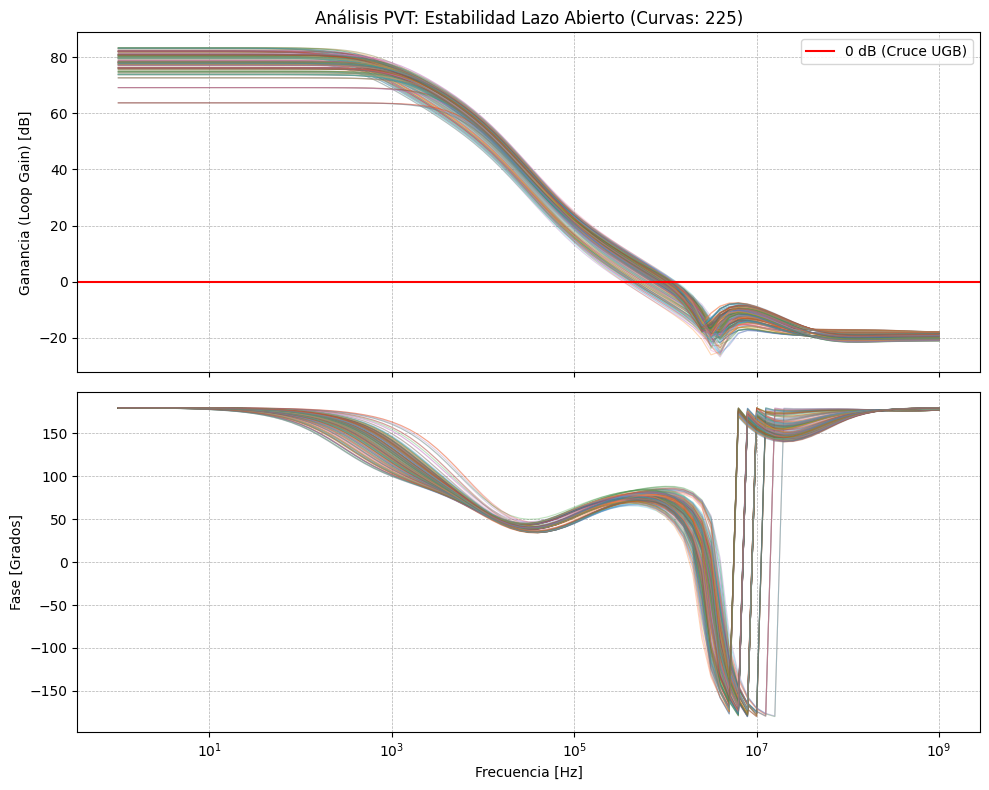

In [17]:
# ====================================================================
# 3. GRAFICAR ESTABILIDAD (Bode: Ganancia de Lazo y Margen de Fase)
# ====================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
exitosas_estab = 0

for llave, curvas in graficas_ldo.items():
    # Verificamos que las llaves existan en el diccionario
    if "frecuencia" in curvas and "ganancia" in curvas and "fase" in curvas:
        x_freq = np.abs(curvas["frecuencia"])
        y_gain = np.real(curvas["ganancia"])
        y_phase = np.real(curvas["fase"])
        
        # Graficamos ambas (el eje X lo comparten)
        ax1.semilogx(x_freq, y_gain, linewidth=0.8, alpha=0.3)
        ax2.semilogx(x_freq, y_phase, linewidth=0.8, alpha=0.3)
        
        exitosas_estab += 1

# --- Configuración de la gráfica de Ganancia ---
ax1.set_title(f"Análisis PVT: Estabilidad Lazo Abierto (Curvas: {exitosas_estab})")
ax1.set_ylabel("Ganancia (Loop Gain) [dB]")
ax1.grid(True, which="both", linestyle="--", linewidth=0.5)
ax1.axhline(0, color='red', linestyle='-', linewidth=1.5, label="0 dB (Cruce UGB)")
ax1.legend(loc="upper right")

# --- Configuración de la gráfica de Fase ---
ax2.set_xlabel("Frecuencia [Hz]")
ax2.set_ylabel("Fase [Grados]")
ax2.grid(True, which="both", linestyle="--", linewidth=0.5)
# Referencia común de margen de fase (dependiendo de cómo mida Xschem, suele ser 0 o -180)
# ax2.axhline(0, color='black', linestyle='--', linewidth=1) 

# tight_layout ajusta automáticamente los márgenes para que no se vea apretado
plt.tight_layout()
plt.savefig("estabilidad.png", dpi=300, bbox_inches='tight')
plt.show()


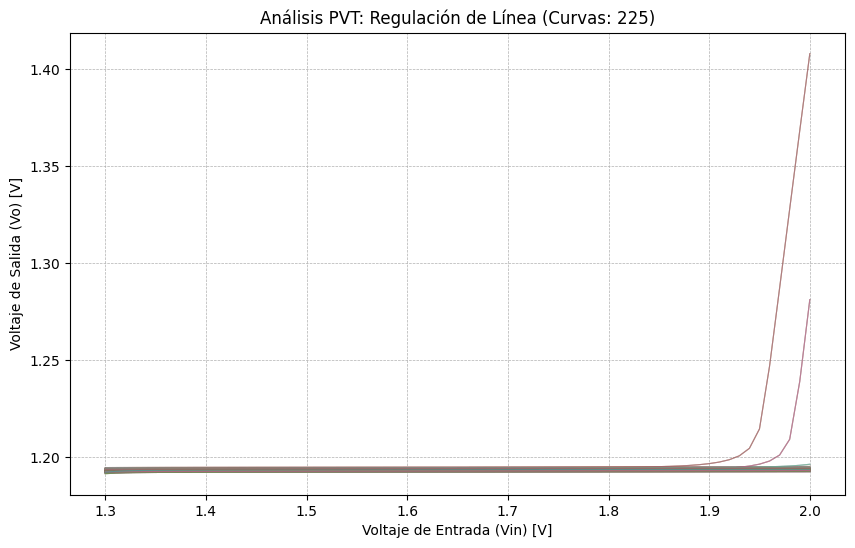

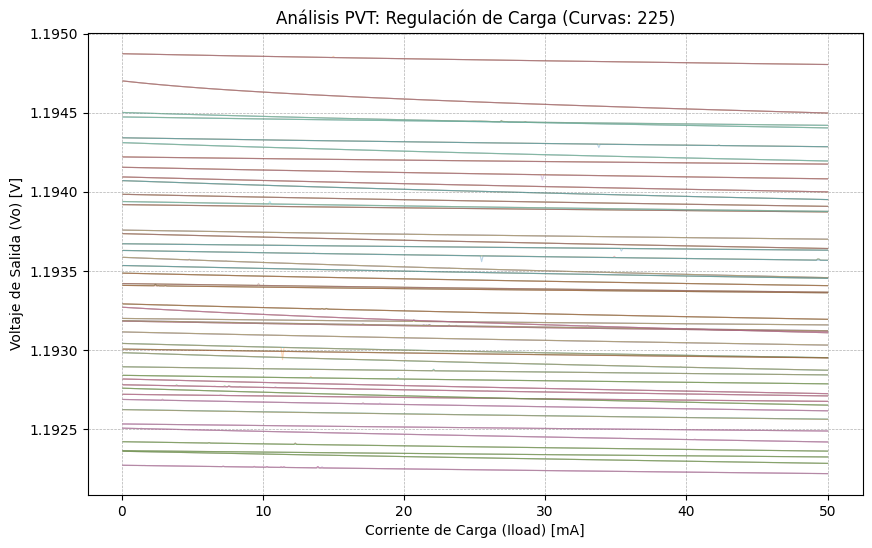

In [19]:
# ====================================================================
# 4. GRAFICAR REGULACIÓN DE LÍNEA (Vout vs Vin)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_line = 0

for llave, curvas in graficas_ldo.items():
    if "dc_vin" in curvas and "dc_vin_vo" in curvas:
        x_vin = np.real(curvas["dc_vin"])
        y_vout_line = np.real(curvas["dc_vin_vo"])
        
        plt.plot(x_vin, y_vout_line, linewidth=0.8, alpha=0.3)
        exitosas_line += 1

plt.title(f"Análisis PVT: Regulación de Línea (Curvas: {exitosas_line})")
plt.xlabel("Voltaje de Entrada (Vin) [V]")
plt.ylabel("Voltaje de Salida (Vo) [V]")
plt.grid(True, linestyle="--", linewidth=0.5)
# Opcional: enfocar el eje Y alrededor de tu voltaje objetivo (ej. 1.2V o 1.8V)
# plt.ylim(1.15, 1.25) 
plt.savefig("grafica_regulacion_linea.png", dpi=300, bbox_inches='tight')
plt.show()

# ====================================================================
# 5. GRAFICAR REGULACIÓN DE CARGA (Vout vs Iload)
# ====================================================================
plt.figure(figsize=(10, 6))
exitosas_load = 0

for llave, curvas in graficas_ldo.items():
    if "dc_iload" in curvas and "dc_iload_vo" in curvas:
        # Multiplicamos por 1000 para pasar de Amperios a miliAmperios (mA)
        x_iload_mA = np.real(curvas["dc_iload"]) * 1000 
        y_vout_load = np.real(curvas["dc_iload_vo"])
        
        plt.plot(x_iload_mA, y_vout_load, linewidth=0.8, alpha=0.3)
        exitosas_load += 1

plt.title(f"Análisis PVT: Regulación de Carga (Curvas: {exitosas_load})")
plt.xlabel("Corriente de Carga (Iload) [mA]")
plt.ylabel("Voltaje de Salida (Vo) [V]")
plt.grid(True, linestyle="--", linewidth=0.5)
# plt.ylim(1.15, 1.25)
plt.savefig("line_regularion.png", dpi=300, bbox_inches='tight')
plt.show()
